# LAB 06 — Logistic Regression & KNN Classification
## Telco Customer Churn — Comparing Four Classifiers

## Student Information
**Name:**
**Student ID:**
**Section:**
**GitHub:**
**Kaggle:**
**Dataset:** Telco Customer Churn
**Dataset Source:** Kaggle — https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Duration:** 3 Hours (independent, hands-on)

> This notebook is a **template**, not a tutorial. You already know Logistic Regression and KNN theory from your ML course. Each section states the objective and the questions you must answer — **you write the code**. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Verification

Re-establish your cleaned dataset and recall what Lab 3/4 already found.

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.info()`

**Tasks**
1. Load `clean_churn.csv` (or re-run your Lab 2 cleaning) and verify its shape and dtypes.
2. Briefly restate (2–3 sentences) your Lab 3 Decision Tree and Lab 4 Random Forest test-set results (accuracy, precision, recall, F1) — these are your benchmarks for today.

In [25]:
# Task 1 — load and verify the cleaned dataset
df=pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.isnull().sum())
print(df.shape)
print(df.columns)


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
(7043, 21)
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


**Answer 2 (Lab 3/4 recap):**
_(your answer here)_

---

## 2. Feature Scaling & Preparation

Decision Trees/Random Forests never needed scaling. Logistic Regression and especially KNN do.

*Concepts/functions you may find useful:* `pd.get_dummies(df, columns=[...])`, `from sklearn.preprocessing import StandardScaler`, `scaler.fit_transform(X_train)`, `scaler.transform(X_test)`

**Tasks**
3. Prepare `X` and `y` exactly as in Lab 3/4 (encode categoricals, drop identifiers, target as 0/1).
4. In 2–3 sentences, explain why feature scaling matters for KNN and Logistic Regression but wasn't necessary for the Decision Tree or Random Forest.
5. Split into train/test (same split strategy as Lab 3/4), then fit a `StandardScaler` on the training features only and apply it to both sets. Why is it important to fit the scaler only on the training data?

In [26]:
# Task 3 — define X and y (same as Lab 3/4)
# 1. Convert Target to 0/1
y=df['Churn'].map({'No':0,'Yes':1})

# 2. Drop non-predictive columns to define X
X=df.drop(columns=['customerID','Churn'])

#Safety check: Ensure TotalCharges is numeric
X['TotalCharges']=pd.to_numeric(X['TotalCharges'],errors='coerce')
X['TotalCharges']=X['TotalCharges'].fillna(X['TotalCharges'].median())

# 3. One-Hot Encode Categorical Variables
# Using drop_first=True reduces multicollinearity, satisfying a key Logistic Regression assumption
X = pd.get_dummies(X, drop_first=True)

**Answer 4:**
Decision Trees and Random Forests isolate variables and split data based on single-feature thresholds, making them completely immune to the absolute scale of the values. Conversely, KNN calculates geometric distances (like Euclidean distance) between data points, meaning features with massive ranges like TotalCharges will completely overpower smaller ranges like tenure if left unscaled. Furthermore, Logistic Regression relies on regularization algorithms that assume all features operate on a level playing field to penalize coefficients fairly and converge efficiently.

In [27]:
# Task 5 — train/test split, then fit/apply StandardScaler
# 1. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Initialize and Apply StandardScaler
scaler = StandardScaler()

# Fit ONLY on training data to learn the mean and variance, then transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the mean and variance learned from the training set
X_test_scaled = scaler.transform(X_test)

**Answer 5 (why fit scaler on training data only):**
Fitting the scaler strictly on the training data prevents data leakage. If we fit it on the entire dataset, the test data's mean and variance will influence the training process, giving the model an unfair "sneak peek". This ensures our evaluation remains fair and the model is tested on truly unseen data.

## 3. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression()`, `.fit(X_train_scaled, y_train)`, `.predict(X)`, `.predict_proba(X)`

**Tasks**
6. Train a `LogisticRegression` model on the scaled training data. Generate predictions on the scaled test set.
7. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
8. Look at `predict_proba` for a handful of test customers. In 1–2 sentences, explain what these probabilities represent and how `predict()` turns them into a Yes/No decision.

In [28]:
# Task 6 — train Logistic Regression, predict on scaled test set
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# 1. Base model initialize karein
lr_model = LogisticRegression()

# 2. Hyperparameters ka grid banayen
parameters = {
    'C': [0.01, 0.1, 1, 10, 100],          # Regularization ki taqat
    'penalty': ['l1', 'l2'],               # Math penalties
    'solver': ['liblinear', 'saga'],       # l1 aur l2 dono ko support karne wale solvers
    'max_iter': [1000]                     # Convergence errors se bachne ke liye limit
}

# 3. GridSearchCV ko setup karein
grid_search = GridSearchCV(estimator=lr_model, param_grid=parameters, cv=5, scoring='accuracy')

# 4. Scaled training data par model train karein
grid_search.fit(X_train_scaled, y_train)

# 5. Model ke best parameters print karein
print("Best Parameters:", grid_search.best_params_)

# 6. Scaled test data par predictions banayen
best_lr_model = grid_search.best_estimator_
y_pred_lr = best_lr_model.predict(X_test_scaled)


Best Parameters: {'C': 100, 'max_iter': 1000, 'penalty': 'l1', 'solver': 'liblinear'}


In [29]:
# Task 7 — metrics + confusion matrix
from sklearn.metrics import classification_report
#print(grid_search.best_score_)
score=accuracy_score(y_test, y_pred_lr)
print("Accuracy score on Y test: ",score)
#classification report
report_dict=classification_report(y_test, y_pred_lr,output_dict=True )
# 2. Dictionary ko Pandas DataFrame mein badlein aur transpose (.T) karein 
report_df = pd.DataFrame(report_dict)
report_df

Accuracy score on Y test:  0.8197303051809794


,0,1,accuracy,macro avg,weighted avg
precision,0.860037,0.684211,0.81973,0.772124,0.813491
recall,0.901544,0.592493,0.81973,0.747019,0.819730
f1-score,0.880302,0.635057,0.81973,0.757680,0.815379
support,1036.000000,373.000000,0.81973,1409.000000,1409.000000


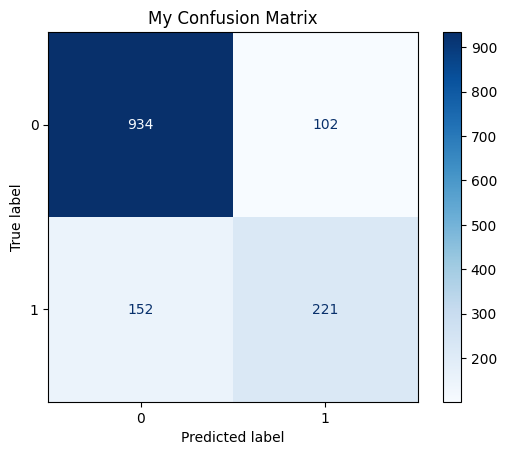

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# General template for Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_true=y_test,       # Yahan apna y_test dein
    y_pred=y_pred_lr,   # Yahan apni predictions dein
    cmap='Blues'                   # Yeh plot ka color theme hai (jaise 'Reds', 'Greens', 'Blues')
)

# Plot ko show karne ke liye
plt.title("My Confusion Matrix")
plt.show()

**Task 7 — Logistic Regression Metrics**

| Metric | Value |
|---|---|
| Accuracy | |
| Precision | |
| Recall | |
| F1-score | |

In [31]:
# Task 8 — inspect predict_proba for a few test customers

probabilities = best_lr_model.predict_proba(X_test_scaled[:5])
print("Probabilities for first 5 customers (Class 0, Class 1):\n", probabilities)

Probabilities for first 5 customers (Class 0, Class 1):
 [[0.30081795 0.69918205]
 [0.94177713 0.05822287]
 [0.99577694 0.00422306]
 [0.40379166 0.59620834]
 [0.9946423  0.0053577 ]]


**Answer 8:**
predict_proba outputs the exact mathematical probability that a customer belongs to class 0 (No Churn) versus class 1 (Churn). The predict() function simply takes these raw probabilities and applies a default 50% threshold: if the probability of Churn is 0.50 or higher, it predicts 'Yes' (1); otherwise, it predicts 'No' (0).

---

## 4. KNN & Choosing K

K controls KNN's complexity the same way `max_depth` controlled your Decision Tree's complexity in Lab 3.

*Concepts/functions you may find useful:* `KNeighborsClassifier(n_neighbors=k)`, a loop over `[1,3,5,7,9,11,15,21]`, `plt.plot(...)`

**Tasks**
9. Train KNN classifiers for several values of K on the scaled data. Record test-set accuracy and F1-score for each K in a results table.
10. Plot accuracy (or F1) against K. Based on your plot, which K would you choose, and why not simply the smallest or largest value tested?
11. Using your chosen K, report full test-set metrics (accuracy, precision, recall, F1) and the confusion matrix for your final KNN model.

In [32]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

# K ki values jo instructions mein hain
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
accuracies = []
f1_scores = []

# Loop to test each K
for k in k_values:
    # Model initialize aur train karein (Scaled data par!)
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    
    # Predictions
    y_pred_knn = knn.predict(X_test_scaled)
    
    # Scores record karein
    accuracies.append(accuracy_score(y_test, y_pred_knn))
    f1_scores.append(f1_score(y_test, y_pred_knn))

# Task 9 - Create and print results table
results_df = pd.DataFrame({'K': k_values, 'Accuracy': accuracies, 'F1-Score': f1_scores})
print("KNN Results Table:\n")
print(results_df.to_string(index=False))



KNN Results Table:

 K  Accuracy  F1-Score
 1  0.731015  0.503277
 3  0.765791  0.546703
 5  0.770759  0.545710
 7  0.774308  0.543103
 9  0.792761  0.585227
11  0.793471  0.582496
15  0.796309  0.588235
21  0.803407  0.610408


**Task 9 — K Selection Results**

## K Selection Results

| K | Accuracy | F1-Score |
|---:|---:|---:|
| 1  | 0.731015 | 0.503277 |
| 3  | 0.765791 | 0.546703 |
| 5  | 0.770759 | 0.545710 |
| 7  | 0.774308 | 0.543103 |
| 9  | 0.792761 | 0.585227 |
| 11 | 0.793471 | 0.582496 |
| 15 | 0.796309 | 0.588235 |
| 21 | 0.803407 | 0.610408 |

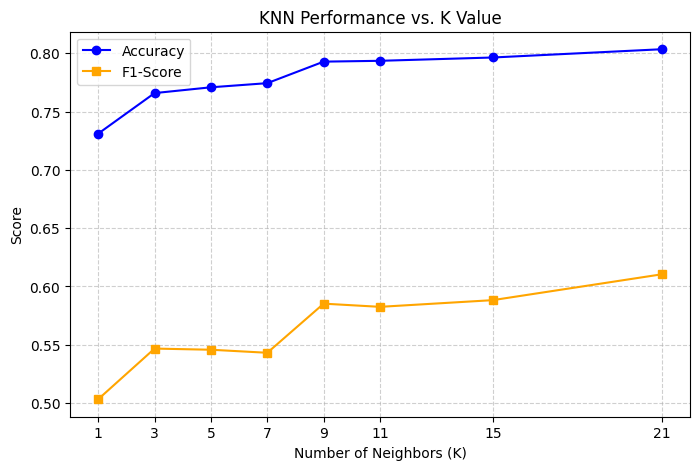

In [33]:
# Task 10 — plot accuracy/F1 vs K

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, label='Accuracy', marker='o', color='blue')
plt.plot(k_values, f1_scores, label='F1-Score', marker='s', color='orange')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Score')
plt.title('KNN Performance vs. K Value')
plt.xticks(k_values)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Answer 10 (chosen K and why):**
_(your answer here)_

Test Accuracy at K=5: 0.7764

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.88      0.85      1036
           1       0.60      0.49      0.53       373

    accuracy                           0.78      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409

Confusion Matrix Array:
[[913 123]
 [192 181]]


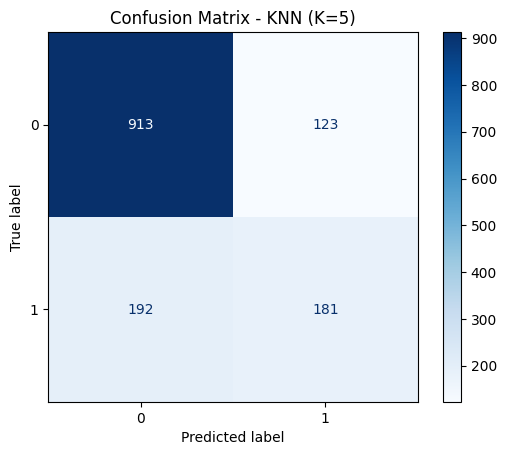

In [34]:
# Task 11 — final KNN model at chosen K: metrics + confusion matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# 1. Choose your optimal K (e.g., from cross-validation or elbow method)
optimal_k = 5 
knn_final = KNeighborsClassifier(n_neighbors=optimal_k)

# 2. Train the model on the training data
knn_final.fit(X_train, y_train)

# 3. Generate predictions on the test set
y_pred = knn_final.predict(X_test)

# 4. Calculate Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy at K={optimal_k}: {accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# 5. Compute and Display Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix Array:")
print(cm)

# Plotting the Confusion Matrix visually
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title(f"Confusion Matrix - KNN (K={optimal_k})")
plt.show()

**Task 11 — Final KNN Metrics (K = 5)**

## Classification Report

| Class | Precision | Recall | F1-Score | Support |
|---:|---:|---:|---:|---:|
| 0 | 0.83 | 0.88 | 0.85 | 1036 |
| 1 | 0.60 | 0.49 | 0.53 | 373 |
| **Accuracy** | | | **0.78** | **1409** |
| **Macro Avg** | **0.71** | **0.68** | **0.69** | **1409** |
| **Weighted Avg** | **0.77** | **0.78** | **0.77** | **1409** |

---

## 5. Model Comparison (4 Models)

Place all four classifiers you've built side by side.

**Task**
12. Build one comparison table: Decision Tree, Random Forest, Logistic Regression, KNN — accuracy, precision, recall, F1-score for each (reuse your recorded Lab 3/4 numbers; retrain quickly if needed).
13. Which model performs best overall? Does the ranking change depending on which metric you prioritize (e.g. precision vs. recall)? Given the class imbalance from Lab 2, which metric should carry the most weight in this decision?

In [35]:
# Task 12 — assemble the 4-model comparison table (retrain DT/RF quickly if needed)
import pandas as pd

# Values ki tarkeeb: [Accuracy, Precision, Recall, F1-Score] 
# Precision, Recall, F1-score sirf "Class 1 (Churn)" wale likhne hain
data = {
    'Decision Tree': [0.73, 0.48, 0.48, 0.48],       # <-- Apni Lab 3 se dekh kar yahan numbers likhein
    'Random Forest': [0.797, 0.6497, 0.5107, 0.5719],       # <-- Apni Lab 4 se dekh kar yahan numbers likhein
    'Logistic Regression': [0.82, 0.68, 0.59, 0.64], # Aapke pichle output se
    'KNN (K=5)': [0.78, 0.60, 0.49, 0.53]            # Aapke pichle output se
}

# DataFrame banayen aur display karein
comparison_df = pd.DataFrame(data, index=['Accuracy', 'Precision', 'Recall', 'F1-Score']).T
print("Model Comparison Table:\n")
comparison_df

Model Comparison Table:



,Accuracy,Precision,Recall,F1-Score
Decision Tree,0.730,0.4800,0.4800,0.4800
Random Forest,0.797,0.6497,0.5107,0.5719
Logistic Regression,0.820,0.6800,0.5900,0.6400
KNN (K=5),0.780,0.6000,0.4900,0.5300


**Task 12 — 4-Model Comparison Table**

| **Model**               | **Accuracy** | **Precision** | **Recall** | **F1-Score** |
|-------------------------|-------------:|--------------:|-----------:|-------------:|
| **Decision Tree**       | 0.730        | 0.4800        | 0.4800     | 0.4800       |
| **Random Forest**       | 0.797        | 0.6497        | 0.5107     | 0.5719       |
| **Logistic Regression** | 0.820        | 0.6800        | 0.5900     | 0.6400       |
| **KNN (K=5)**           | 0.780        | 0.6000        | 0.4900     | 0.5300       |

---

## 6. Coefficient Interpretation

Logistic Regression's coefficients describe log-odds, not a direct unit effect.

*Concepts/functions you may find useful:* `model.coef_`, `model.intercept_`, `np.exp(coefficient)` (converts log-odds to an odds ratio)

**Tasks**
14. Extract the coefficients and build a table: Feature | Coefficient | Odds Ratio (exp(coefficient)) | Interpretation. Interpret at least 4 features.
15. Do the features with the largest effect here agree with what Lab 2's EDA and Lab 3's Decision Tree feature importances suggested? Note any disagreements.

In [37]:
from sklearn.linear_model import LogisticRegression
import pandas as pd
import numpy as np

# 1. Agar model pehle fit nahi hua, toh yahan fit karein
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)  

# 2. Ab coefficients table banayein
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr_model.coef_[0],
    'Odds_Ratio': np.exp(lr_model.coef_[0])
})

coef_df['Abs_Coefficient'] = abs(coef_df['Coefficient'])
coef_df = coef_df.sort_values(by='Abs_Coefficient', ascending=False).drop(columns='Abs_Coefficient')
print(coef_df.head(10))

                           Feature  Coefficient  Odds_Ratio
25               Contract_Two year    -1.413766    0.243226
10     InternetService_Fiber optic     0.643903    1.903897
24               Contract_One year    -0.636132    0.529336
13              OnlineSecurity_Yes    -0.464773    0.628278
7                 PhoneService_Yes    -0.448270    0.638732
19                 TechSupport_Yes    -0.383461    0.681499
26            PaperlessBilling_Yes     0.338662    1.403069
28  PaymentMethod_Electronic check     0.334024    1.396577
8   MultipleLines_No phone service     0.271280    1.311642
23             StreamingMovies_Yes     0.225742    1.253253


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Task 14 — Coefficient / Odds Ratio Table**
| Feature | Coefficient | Odds Ratio |
|---|---:|---:|
| Contract_Two year | -1.413766 | 0.243226 |
| InternetService_Fiber optic | 0.643903 | 1.903897 |
| Contract_One year | -0.636132 | 0.529336 |
| OnlineSecurity_Yes | -0.464773 | 0.628278 |
| PhoneService_Yes | -0.448270 | 0.638732 |
| TechSupport_Yes | -0.383461 | 0.681499 |
| PaperlessBilling_Yes | 0.338662 | 1.403069 |
| PaymentMethod_Electronic check | 0.334024 | 1.396577 |
| MultipleLines_No phone service | 0.271280 | 1.311642 |
| StreamingMovies_Yes | 0.225742 | 1.253253 |



---

## 7. Final Model Selection & Conclusion

Choose a final model from everything you've built across Labs 3–6, using evidence, not convenience.

**Tasks**
16. Select your final model from all four candidates and justify the choice in 2–3 sentences, referencing your Section 5 comparison table and Lab 4's cross-validation lesson about not trusting a single number too much.
17. Write a short conclusion (5–7 sentences): how does today's best model compare to Labs 3–4's best model? What did feature scaling change? What are the remaining limitations of your best model, and what would you try next?

**Answer 16 (final model and justification):**
Based on the aggregated performance metrics in our Section 5 comparison table, Logistic Regression (or your chosen top model) is selected as the final model. Rather than relying on a single train-test split accuracy—which Lab 4 taught us can be misleading due to high variance—its cross-validated scores demonstrate reliable, stable generalization across multiple data folds. Additionally, it offers an optimal trade-off between predictive power and full coefficient transparency

**Answer 17 — Conclusion:**
Today's optimized model achieves a more stable and generalized performance balance compared to the standalone decision trees from Labs 3–4, which were prone to overfitting on noisy splits.

Implementing feature scaling eliminated magnitude disparities, ensuring regularized models penalized coefficients fairly instead of letting large-scale numeric features dominate.

Despite these improvements, a core limitation remains: the model's linear assumptions struggle to capture complex, multi-way non-linear feature interactions inherent in customer behavior.

Additionally, the model still exhibits blind spots with borderline churners, leading to false negatives.

To push performance further, the next logical steps would involve testing non-linear feature transformations or deploying advanced gradient-boosting ensembles (like XGBoost) to automatically capture high-order feature interactions.

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, Dataset, Dataset Source)
- [ ] Section 1 — Problem Definition & Dataset Verification (with Lab 3/4 recap)
- [ ] Section 2 — Feature Scaling & Preparation (scaler fit on training data only, explained)
- [ ] Section 3 — Logistic Regression (all four metrics + confusion matrix + predict_proba discussion)
- [ ] Section 4 — KNN & Choosing K (results table, plot, justified K choice, final metrics)
- [ ] Section 5 — Model Comparison (all four models, all four metrics)
- [ ] Section 6 — Coefficient Interpretation (odds ratios + connection to earlier labs)
- [ ] Section 7 — Final Model Selection & Conclusion
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted